# Lab 04 — Data Understanding & Exploratory Data Analysis (EDA)
**Tools:** Pandas · NumPy · Matplotlib

## Learning outcomes
By completing this notebook, you will be able to:
- inspect a dataset’s structure and variable types;
- summarize numerical data using descriptive statistics;
- identify missing values and investigate unusual observations;
- explore distributions and relationships using visualizations;
- communicate findings supported by evidence.

> **Instructions:** Complete each `TODO`, run the cells in order, and write brief interpretations. An unusual value is not automatically an error—investigate before deciding how to handle it.


## 1. Load the dataset

The Palmer Penguins dataset contains measurements of penguins from different species and islands. Load the CSV directly from the provided URL.

In [2]:
%pip install pandas

   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.7 MB 1.8 MB/s eta 0:00:06
   - -------------------------------------- 0.5/10.7 MB 1.8 MB/s eta 0:00:06
   -- ------------------------------------- 0.8/10.7 MB 1.2 MB/s eta 0:00:09
   ---- ----------------------------------- 1.3/10.7 MB 1.3 MB/s eta 0:00:08
   ----- ---------------------------------- 1.6/10.7 MB 1.4 MB/s eta 0:00:07
   ------ --------------------------------- 1.8/10.7 MB 1.3 MB/s eta 0:00:07
   ------ --------------------------------- 1.8/10.7 MB 1.3 MB/s eta 0:00:07
   ------- -------------------------------- 2.1/10.7 MB 1.2 MB/s eta 0:00:08
   -------- ------------------------------- 2.4/10.7 MB 1.2 MB/s eta 0:00:07
   --------- ------------------------------ 2.6/10.7 MB 1.2 MB/s eta 0:00:07
   ---------- ----------------------------- 2.9/10.7 MB 1.2 MB/s eta 0:00:07
   ----------

In [4]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 592.7 kB/s eta 0:00:15
   --- ------------------------------------ 0.8/9.3 MB 820.6 kB/s eta 0:00:11
   ---- ----------------------------------- 1.0/9.3 MB 926.6 kB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.3 MB 959.4 kB/s eta 0:00:09
   ------ --------------------------------- 1.6/9.3 MB 984.4 kB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.3 MB 1.0 MB/s eta 0:00:08
   -------- ------------------------------- 2.1/9.3 MB 1.0 MB/s eta 0:00:08
   ---------- ----------------------------- 2.4/9.3 MB 1.0 MB/s eta 0:00:07
   ---------- ----------------------------- 2.4/9.3 MB 1.0 MB/s eta 0:00:07
   ----------- ---------------------------- 2.6/9.3 MB 1.0 MB/s eta 0:00:07
   ------------ -------

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"

# TODO 1: Load the CSV into a DataFrame named df
# Hint: use pd.read_csv(url)
df =pd.read_csv(url)

# TODO 2: Display the first five rows
# Hint: use the DataFrame head() method
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## 2. Understand the dataset

Inspect the dataset before analyzing it.

**Complete the tasks:**
1. Find the number of rows and columns.
2. Inspect column names and data types.
3. Display summary statistics.
4. Count observations in each penguin species.

In [6]:
# TODO 1: Display the number of rows and columns
# Hint: df.shape
print(df.shape)

# TODO 2: Display the column names and data types
# Hints: df.columns and df.dtypes
print(df.columns)
print(df.dtypes)

# TODO 3: Inspect non-missing counts and data types
# Hint: df.info()
df.info()

# TODO 4: Summarize numerical columns
# Hint: df.describe()
df.describe()

# TODO 5: Count observations for each species
df['species'].value_counts()

(344, 8)
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), s

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

**Interpret your results**

- How many observations and variables are in the dataset?
- Which variables are numerical, and which are categorical?
- Are the species represented equally?

Write your answers below.

**Your observations:**  
TODO: Write 2–3 sentences here.

## 3. Assess data quality

Missing values can affect summaries and visualizations. First, identify where they occur; do not remove rows automatically.

In [7]:
# TODO 1: Count missing values in each column
missing_counts =df.isnull().sum()
display(missing_counts)

# TODO 2: Calculate the percentage of missing values in each column

missing_percent = (df.isnull().sum() / len(df)) * 100
display(missing_percent.round(2))

# TODO 3: Display rows that contain at least one missing value
rows_with_missing = df[df.isnull().any(axis=1)]
display(rows_with_missing.head())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
year                 0.00
dtype: float64

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007


**Interpret your results**

- Which columns contain missing values?
- How might missing values affect your analysis?
- What additional information would help you decide how to handle them?

**Your observations:**  
TODO: Write 2–3 sentences here.

## 4. Explore numerical variables

Use descriptive statistics to understand the center and spread of a variable. In this section, focus on `body_mass_g`.

In [8]:
# Select body mass and exclude missing values
body_mass = df["body_mass_g"].dropna()

# TODO 1: Calculate the mean and median using NumPy
# Hints: np.mean(body_mass), np.median(body_mass)
mean_mass =np.mean(body_mass)
median_mass =np.median(body_mass)
print("Mean:", mean_mass)
print("Median:", median_mass)

# TODO 2: Find the minimum and maximum
# Hints: body_mass.min(), body_mass.max()
print("Minimum:", body_mass.min())
print("Maximum:", body_mass.max())

# TODO 3: Calculate standard deviation and quartiles
# Hints: np.std(body_mass); np.percentile(body_mass, [25, 50, 75])
std_mass = np.std(body_mass)
quartiles = np.percentile(body_mass, [25, 50, 75])
# TODO 4: Display the five smallest and five largest body-mass values
# Hint: use nsmallest(5) and nlargest(5)
print("Five smallest body masses:")
print(body_mass.nsmallest(5))

print("Five largest body masses:")
print(body_mass.nlargest(5))

Mean: 4201.754385964912
Median: 4050.0
Minimum: 2700.0
Maximum: 6300.0
Five smallest body masses:
314    2700.0
58     2850.0
64     2850.0
54     2900.0
98     2900.0
Name: body_mass_g, dtype: float64
Five largest body masses:
169    6300.0
185    6050.0
229    6000.0
269    6000.0
231    5950.0
Name: body_mass_g, dtype: float64


**Interpret your results**

- How different are the mean and median?
- What do the minimum and maximum tell you?
- Do any values deserve further investigation? Explain why.

**Your observations:**  
TODO: Write 2–3 sentences here.

## 5. Visualize distributions

A histogram helps reveal the shape of a numerical distribution. Create a histogram of body mass and label it clearly.

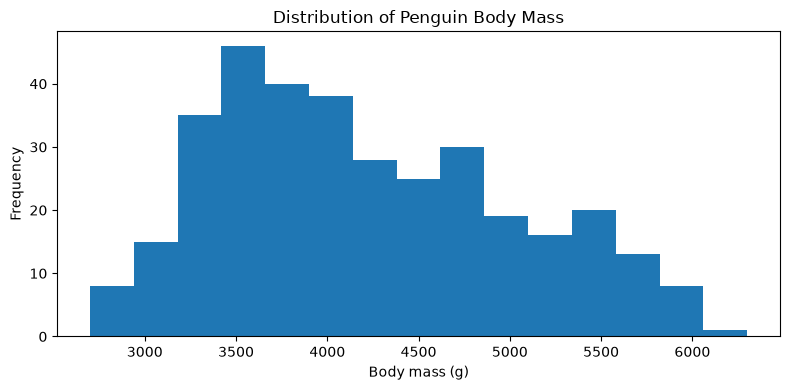

In [9]:
# Missing values are excluded for this histogram
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(8, 4))

# TODO: Create a histogram
# Hint: plt.hist(mass_values, bins=15)
plt.hist(mass_values, bins=15)
plt.xlabel("Body mass (g)")
plt.ylabel("Frequency")
plt.title("Distribution of Penguin Body Mass")
plt.tight_layout()
plt.show()

**Interpret the histogram**

- Where are most observations concentrated?
- Does the distribution appear symmetric or skewed?
- Are there any values that may need further investigation?

**Your interpretation:**  
TODO: Write 2–3 sentences here.

## 6. Explore relationships

A scatter plot helps investigate how two numerical variables vary together. Explore flipper length and body mass.

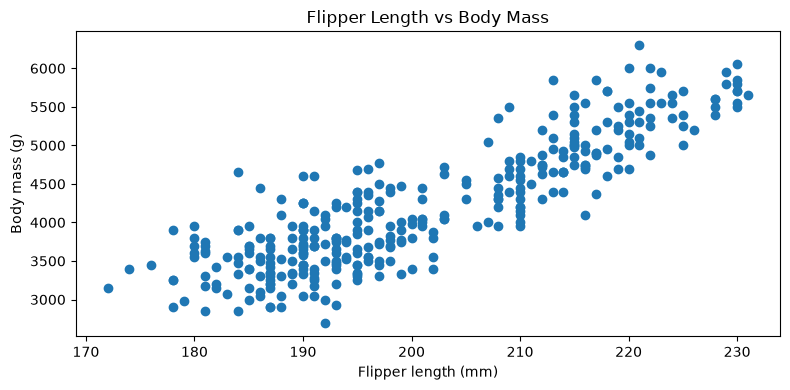

In [10]:
# Keep only rows where both plotted variables are present
plot_data = df[["flipper_length_mm", "body_mass_g"]].dropna()

plt.figure(figsize=(8, 4))

# TODO: Create a scatter plot
# Hint: plt.scatter(x_values, y_values)
# x = plot_data["flipper_length_mm"]
# y = plot_data["body_mass_g"]
x = plot_data["flipper_length_mm"]
y = plot_data["body_mass_g"]
plt.scatter(x, y)

plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Flipper Length vs Body Mass")
plt.tight_layout()
plt.show()

**Interpret the scatter plot**

- Does the plot suggest a positive, negative, or unclear relationship?
- Do you see clusters or points far from the main pattern?
- Does a relationship between two variables prove that one causes the other?

**Your interpretation:**  
TODO: Write 2–3 sentences here.

## 7. Compare groups

Compare average body mass across penguin species. Grouped summaries help reveal differences between categories.

In [11]:
# TODO 1: Calculate mean body mass for each species
# Hint: groupby("species")["body_mass_g"].mean()
mean_by_species =df.groupby("species")["body_mass_g"].mean()
display(mean_by_species)

# TODO 2: Calculate median body mass for each species
# Hint: replace mean() with median()
median_by_species =df.groupby("species")["body_mass_g"].median()
display(median_by_species)

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

species
Adelie       3700.0
Chinstrap    3700.0
Gentoo       5000.0
Name: body_mass_g, dtype: float64

**Interpret your results**

- Which species has the highest mean body mass?
- Does the group comparison tell the same story as the overall histogram?
- What limitation should you keep in mind when comparing group averages?

**Your observations:**  
TODO: Write 2–3 sentences here.

## 8. Investigate potential outliers

A box plot can highlight observations far from the central range. Such observations are potential outliers, not automatically errors.

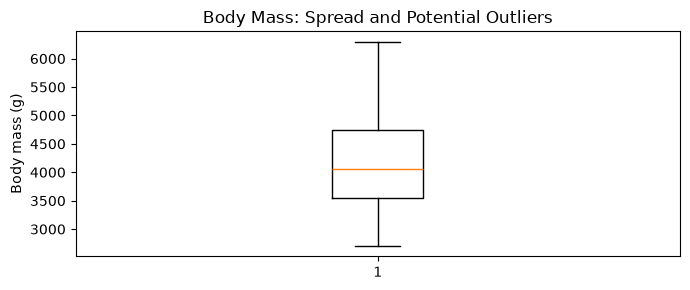

In [12]:
# Exclude missing body-mass values before plotting
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(7, 3))

# TODO: Create a box plot
# Hint: plt.boxplot(mass_values)
plt.boxplot(mass_values)

plt.ylabel("Body mass (g)")
plt.title("Body Mass: Spread and Potential Outliers")
plt.tight_layout()
plt.show()

**Key principle:** EDA is not just producing statistics and plots. It is using them to understand the data, ask better questions, and make careful, evidence-based decisions.